*English follows Dutch*

*Dutch*

# Wisselkoersen vergelijken tussen DEGIRO en European Central Bank

Wisselkoersen van diverse aanbieders verschillen. Dit notebook vergelijkt de wisselkoersen (FX) van de DEGIRO met die van de Europese Centrale Bank (ECB). Een T-test wijst uit dat op een 95% betrouwbaarheidsinterval de nul-hypothese -de wisselkoersen zijn gelijk- *niet* verworpen kan worden. 

*English*

# Comparing exchange rates between DEGIRO and the European Central Bank

Exchange rates from various providers differ. This notebook compares the exchange rates (FX) between DEGIRO and the European Central Bank. A T-test demonstrates that on a 95% confidence interval the null-hypothesis -exchange rates are the same- *cannot* be rejected.

In [64]:
import requests
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from src.functions import read_account_overview, dividends

In [65]:
# Load account statement (.csv file) into dataframe
df_account = read_account_overview('Account-private.csv')
df_dividends = dividends(df_account, 'EUR')

/Users/jurnheinen/Python/degiro_analyser/src/functions.py:81: FutureWarning: Setting an item of incompatible dtype is deprecated and will raise an error in a future version of pandas. Value '[1.2228 1.1789 1.1862 1.1588 1.1355 1.1095 1.0509 0.984  1.0688    nan
 1.0892 1.0592 1.0969 1.0816    nan 1.1205 1.0433    nan 1.108  1.1787
 1.1744]' has dtype incompatible with int64, please explicitly cast to a compatible dtype first.
  df_fx.loc[mask, "FX"] = df_fx.loc[mask, "FX_source"]


In [57]:
def get_usd_to_eur_rate(date_str):
    """
    Fetches the USD → EUR exchange rate on a given date (YYYY-MM-DD).
    """
    url = f"https://api.frankfurter.app/{date_str}?from=EUR&to=USD"
    resp = requests.get(url)
    data = resp.json()

    return data["rates"]["USD"]

In [75]:
# Get FX rates and the correspnding valuta dates from DEGIRO 
degiro_fx_list, valuta_dates_list = df_account[df_account['FX'].notna()][['FX', 'Valutadatum']].T.values.tolist()

# Typecasting datetime object to string
valuta_dates_list = [valuta_date.strftime("%Y-%m-%d") for valuta_date in valuta_dates_list]

# Get FX rates from frankfurter API
frankfurter_fx_list = np.array([get_usd_to_eur_rate(valuta_date) for valuta_date in valuta_dates_list])

# Typecast FX values to floats
degiro_fx_list = np.array([float(fx) for fx in degiro_fx_list])

In [78]:
# Print exchrange rates of the ECB, DEGIRO, the difference and the relative difference
print(f"FX(ECB) \t FX(DEGIRO) \t Diff. \t Rel. Diff. ")
for degiro_fx, frankfurter_fx in zip(degiro_fx_list, frankfurter_fx_list):
    fx_diff = frankfurter_fx - degiro_fx
    fx_rel_diff = (fx_diff / degiro_fx) * 100
    print(f"{frankfurter_fx:.4f} \t\t {degiro_fx} \t {fx_diff:.4f} \t {fx_rel_diff:.3f}")

FX(ECB) 	 FX(DEGIRO) 	 Diff. 	 Rel. Diff. 
1.2271 		 1.2228 	 0.0043 	 0.352
1.2276 		 1.2254 	 0.0022 	 0.180
1.2025 		 1.2044 	 -0.0019 	 -0.158
1.2028 		 1.2081 	 -0.0053 	 -0.439
1.1746 		 1.1756 	 -0.0010 	 -0.085
1.1746 		 1.1789 	 -0.0043 	 -0.365
1.1884 		 1.1862 	 0.0022 	 0.185
1.1579 		 1.1588 	 -0.0009 	 -0.078
1.1334 		 1.1355 	 -0.0021 	 -0.185
1.1101 		 1.1095 	 0.0006 	 0.054
1.0387 		 1.0509 	 -0.0122 	 -1.161
0.9706 		 0.984 	 -0.0134 	 -1.362
1.0649 		 1.0688 	 -0.0039 	 -0.365
1.0847 		 1.0871 	 -0.0024 	 -0.221
1.0938 		 1.0892 	 0.0046 	 0.422
1.0539 		 1.0592 	 -0.0053 	 -0.500
1.0872 		 1.0887 	 -0.0015 	 -0.138
1.0868 		 1.0809 	 0.0059 	 0.546
1.0956 		 1.0969 	 -0.0013 	 -0.119
1.0811 		 1.0816 	 -0.0005 	 -0.046
1.0689 		 1.0707 	 -0.0018 	 -0.168
1.1155 		 1.1205 	 -0.0050 	 -0.446
1.0444 		 1.0433 	 0.0011 	 0.105
1.1097 		 1.108 	 0.0017 	 0.153
1.1782 		 1.1787 	 -0.0005 	 -0.042
1.1754 		 1.1744 	 0.0010 	 0.085


# T-test analysis to determine if DEGIRO and Frankfurter FX rates are equal.
- Consider a 95% confidence interval using significance level 0.5 (probability of rejecting the null hypothesis when it is true)
- Check if the residuals are normally distributed using Shapiro-Wilk test
- Dataset consists of 26 exchange rates between 2020 and 2025

In [70]:
# Assumptions
# 1. Variances are unequal
# 2. Confidence interval = 95% (alpha = 0.05)
t_stat, pvalue = stats.ttest_ind(degiro_fx_list, frankfurter_fx_list, equal_var=False)

# Define significance level at 0.05
alpha = 0.05

if pvalue < alpha:
    print("Difference in FX rates")
else:
    print("No difference in FX rates")

No difference in FX


Normality of residuals hold


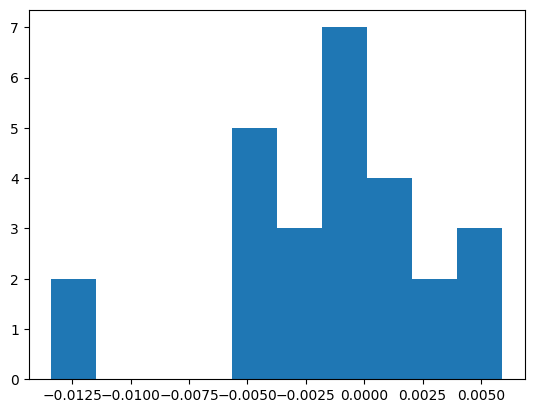

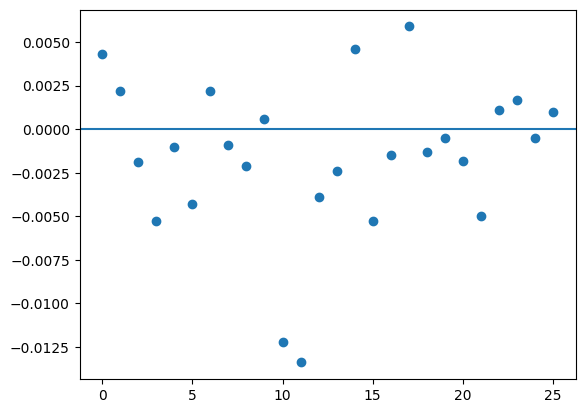

In [71]:
# Calculate residuals
residuals = frankfurter_fx_list - degiro_fx_list

# Perform Shapiro-Wilk test for normality.
shapiro_stat, shapiro_p = stats.shapiro(residuals)

if shapiro_p > alpha:
    print("Normality of residuals holds")
else:
    print("Normality of residual does not holds")

# plot histogram of residuals
plt.hist(residuals)
plt.show()

plt.plot(residuals, 'o')
plt.axhline(0)
plt.show()